# Lab 2 Pre-Lab: Introduction to Pandas

🔥 Note: If you are unfamilar with Pandas dataframes or Matplotlib, please refer to the Common Python Libraries tutorial!

##1. Indexing and Slicing Data

Indexing and slicing can be particularly useful if we are given large amounts of collected data and we are looking for specific sections of data to analyze.
Below, we will be taking a look at a dataset containing information about the [top 100 movies from 2003 to 2022](https://www.kaggle.com/datasets/georgescutelnicu/top-100-popular-movies-from-2003-to-2022-imdb).

First, let's load in our data:

In [1]:
# Adding to plot using matplotlib
%matplotlib inline
# make sure to ignore warnings
import warnings
warnings.simplefilter('ignore')
# Import statement for pandas
import pandas as pd

# Load in our movies dataset
movies = pd.read_csv('movies.csv')

In [2]:
# This is just a small configuration change for purposes of the class
pd.options.display.max_rows = 4

# output some rows of the dataset just to get a better feel for the information
movies

,Title,Rating,Year,Month,Certificate,Runtime,Directors,Stars,Genre,Filming_location,Budget,Income,Country_of_origin
0,Avatar: The Way of Water,7.8,2022,December,PG-13,192,James Cameron,"Sam Worthington, Zoe Saldana, Sigourney Weaver...","Action, Adventure, Fantasy",New Zealand,"$350,000,000","$2,267,946,983",United States
1,Guillermo del Toro's Pinocchio,7.6,2022,December,PG,117,"Guillermo del Toro, Mark Gustafson","Ewan McGregor, David Bradley, Gregory Mann, Bu...","Animation, Drama, Family",USA,"$35,000,000","$108,967","United States, Mexico, France"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1998,Ong-Bak: The Thai Warrior,7.1,2003,February,R,105,Prachya Pinkaew,"Tony Jaa, Phetthai Vongkumlao, Pumwaree Yodkam...","Action, Crime, Thriller",Thailand,Unknown,"$20,235,426","Thailand, France, Hong Kong"
1999,Open Water,5.8,2003,August,R,79,Chris Kentis,"Blanchard Ryan, Daniel Travis, Saul Stein, Mic...","Adventure, Drama, Horror",Bahamas,"$500,000","$54,683,487",United States


Next, we can use indexing to pull information that we are interested in looking at:

In [ ]:
# Output names of columns in the dataset.
movies.columns

Index(['Title', 'Rating', 'Year', 'Month', 'Certificate', 'Runtime',
       'Directors', 'Stars', 'Genre', 'Filming_location', 'Budget', 'Income',
       'Country_of_origin'],
      dtype='str')

Another example, we can look specifically for data by name, category, etc.
Below, we look for movies filmed in Canada:

In [ ]:
# select location
filmed_in_CA = 'Canada'
# Can slice dataset to look for data of a single location.
movies[movies.Filming_location == filmed_in_CA]

# Alternate writing. This way can be useful when the column name has an uncommon character in it like :/&/@/$.
# For now we've cleaned all the columns so that you don't have to worry about this.
# Ex:
#movies[movies['Filming_location'] == filmed_in_CA]

,Title,Rating,Year,Month,Certificate,Runtime,Directors,Stars,Genre,Filming_location,Budget,Income,Country_of_origin
7,Violent Night,6.9,2022,December,R,112,Tommy Wirkola,"David Harbour, John Leguizamo, Beverly D Angel...","Action, Comedy, Crime",Canada,"$20,000,000","$59,595,460","United States, Canada"
65,Slumberland,6.7,2022,November,PG,117,Francis Lawrence,"Jason Momoa, Marlow Barkley, Chris O Dowd, Kyl...","Adventure, Comedy, Family",Canada,"$150,000,000",Unknown,United States
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1987,Barely Legal,4.7,2003,May,R,90,David Mickey Evans,"Erik von Detten, Tony Denman, Daniel Farber, S...",Comedy,Canada,Unknown,"$83,439","Germany, United States"
1997,Gothika,5.8,2003,November,R,98,Mathieu Kassovitz,"Halle Berry, Pen lope Cruz, Robert Downey Jr ,...","Horror, Mystery, Thriller",Canada,"$40,000,000","$141,591,324","United States, France, Canada, Spain"


When slicing you can also use a variety of inequality operators such as:

```
< > >= <=
```

Let's look for movies that have a rating higher than 8/10:

In [ ]:
# Search for movies with a rating higher than 8/10
movies[movies.Rating > 8]

,Title,Rating,Year,Month,Certificate,Runtime,Directors,Stars,Genre,Filming_location,Budget,Income,Country_of_origin
22,Everything Everywhere All at Once,8.1,2022,March,R,139,"Dan Kwan, Daniel Scheinert","Michelle Yeoh, Stephanie Hsu, Jamie Lee Curtis...","Action, Adventure, Comedy",USA,"$25,000,000","$103,384,361",United States
27,Top Gun: Maverick,8.4,2022,May,PG-13,130,Joseph Kosinski,"Tom Cruise, Jennifer Connelly, Miles Teller, V...","Action, Drama",USA,"$170,000,000","$1,488,732,821",United States
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1914,Memories of Murder,8.1,2003,May,Not Rated,132,Bong Joon Ho,"Song Kang ho, Kim Sang kyung, Roe ha Kim, Jae ...","Crime, Drama, Mystery",South Korea,"$2,800,000","$1,166,717",South Korea
1917,Finding Nemo,8.2,2003,May,G,100,"Andrew Stanton, Lee Unkrich","Albert Brooks, Ellen DeGeneres, Alexander Goul...","Animation, Adventure, Comedy",USA,"$94,000,000","$940,352,645",United States


##**Q1.** Applying Data Indexing

Now, let's use our data to make recommendations for some  clients with particular taste in movies:

### **Q1.1.** Movie Search Query

Search for movies created between 2005-2010 (inclusive) with a rating of at least 3, with a country of origin of France.

In [3]:
# Movies from 2005-2010 (inclusive), rating of at least 3, country of origin France
france_movies = movies[(movies.Year >= 2005) & (movies.Year <= 2010) &
                       (movies.Rating >= 3) &
                       (movies.Country_of_origin == 'France')]
france_movies

,Title,Rating,Year,Month,Certificate,Runtime,Directors,Stars,Genre,Filming_location,Budget,Income,Country_of_origin
1287,Rubber,5.7,2010,November,R,82,Quentin Dupieux,"Stephen Spinella, Roxane Mesquida, Wings Hause...","Comedy, Fantasy, Horror",USA,"$500,000","$101,729",France
1598,Inside,6.7,2007,June,R,82,"Alexandre Bustillo, Julien Maury","Alysson Paradis, Jean Baptiste Tabourin, Claud...",Horror,France,"€ 2,400,000","$792,184",France


### **Q1.2.** Comparing US vs. South Korea Movies

#### Q1.2a Dataframe Creation
Create a new dataframe containing only movies from the United States and South Korea.

In order to compare, we would like to list the data in desending order by rating.

When displaying the final data, slice the data to display the top 10 movies of the US and South Korea with their country of origin, title, rating, year, certificate, and genre:

In [4]:
pd.options.display.max_rows = 10

# Separate dataframes, sorted by rating (descending)
US_movies = movies[movies.Country_of_origin == 'United States'].sort_values('Rating', ascending=False)
SK_movies = movies[movies.Country_of_origin == 'South Korea'].sort_values('Rating', ascending=False)

# Combined dataframe of US and South Korea movies, sorted by rating (descending)
US_SK_movies = pd.concat([US_movies, SK_movies]).sort_values('Rating', ascending=False)

cols = ['Country_of_origin', 'Title', 'Rating', 'Year', 'Certificate', 'Genre']

print("----Top 10 Movies in USA and SK----")
print("\nUnited States:")
print(US_movies[cols].head(10).to_string(index=False))
print("\nSouth Korea:")
print(SK_movies[cols].head(10).to_string(index=False))

----Top 10 Movies in USA and SK----

United States:
Country_of_origin                             Title  Rating  Year Certificate                        Genre
    United States                          Whiplash     8.5  2014           R                 Drama, Music
    United States                  Django Unchained     8.4  2012           R               Drama, Western
    United States                              Coco     8.4  2017          PG Animation, Adventure, Comedy
    United States                 Avengers: Endgame     8.4  2019       PG-13     Action, Adventure, Drama
    United States Spider-Man: Into the Spider-Verse     8.4  2018          PG Animation, Action, Adventure
    United States                          Hamilton     8.4  2020       PG-13    Biography, Drama, History
    United States                            WALL·E     8.4  2008           G Animation, Adventure, Family
    United States                 Top Gun: Maverick     8.4  2022       PG-13               

#### Q1.2b Visualize Data

Using the new dataframe you have created above, plot the trend of **average movie ratings** in the US and South Korea side-by-side by **year**.

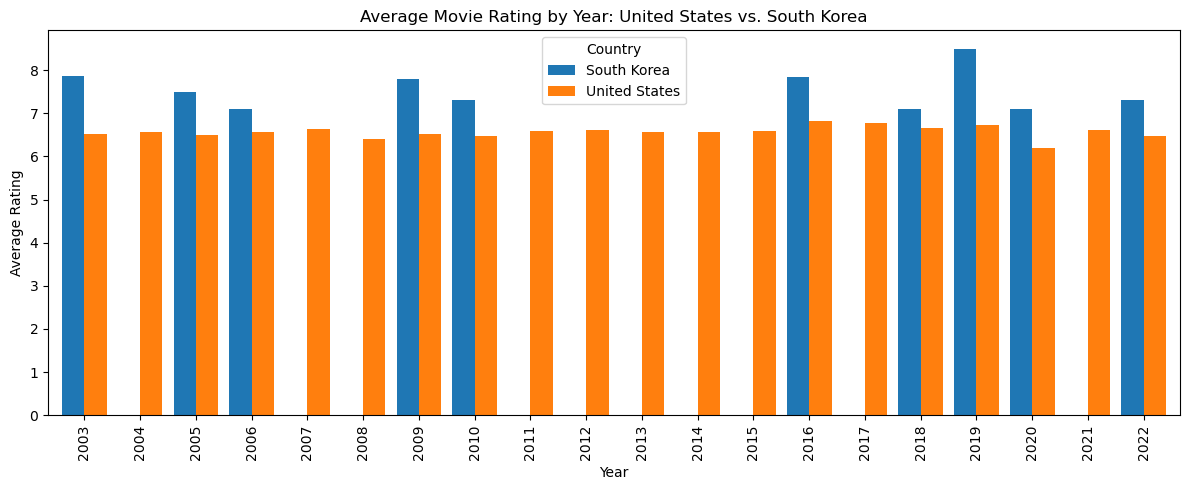

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline

#If you are unfamilar with matplot, please refer to the Introduction to Common Python Libraries under tutorials

# Average rating per year for each country
avg_ratings = (US_SK_movies
               .groupby(['Year', 'Country_of_origin'])['Rating']
               .mean()
               .unstack())

ax = avg_ratings.plot(kind='bar', figsize=(12, 5), width=0.8)
ax.set_title('Average Movie Rating by Year: United States vs. South Korea')
ax.set_xlabel('Year')
ax.set_ylabel('Average Rating')
ax.legend(title='Country')
plt.tight_layout()
plt.show()